In [38]:
# 1. Libraries
from pathlib import Path
import json
import h5py
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from detector_io import load_detector_image

# Choose the detector before running the notebook.
detector = "CMOS"                # "CMOS" or "MCP"

In [39]:
# 2. Detector-dependent loader (analysis below is shared)
def load_image(index):
    return load_detector_image(index, detector, input_folder, image_key)

In [40]:
# 3. Folders and parameters (same settings as the field-series notebook)
input_folder = Path("raw") / detector
output_folder = Path("output") / detector.lower()
azimuthal_folder = output_folder / "azimuthal"
output_folder.mkdir(parents=True, exist_ok=True)
azimuthal_folder.mkdir(parents=True, exist_ok=True)
image_key = "data_22"
center_x, center_y = 1030, 1010
angular_bin_width = 5.0          # degrees; must divide 360
min_pixels = 10
min_coverage = 0.25
mask_path = output_folder / "beamstop_mask.png"  # None disables masking
dark_scan_index = 416 if detector == "CMOS" else None           # None disables dark subtraction

# MCP integers are zero-based indices; filenames are also accepted by load_image.
# Set scan lists/fields for your MCP acquisition before analyzing a series.
if detector == "MCP":
    for index, path in enumerate(sorted(input_folder.glob("*_TDC_2D_*.txt"))):
        print(index, path.name)


In [47]:
# 4. Three scans, each from +300 to -300 mT
scan_ranges = {
    "0°": np.arange(256, 376),
    "22°": np.arange(16, 136),
    "45°": np.arange(136, 256),
    "0°-after": np.arange(444, 564),
}
fields = {label: np.linspace(300, -300, len(indices))
          for label, indices in scan_ranges.items()}
output_range = "16-376"         # upper endpoint excluded

In [48]:
# 5. Beamstop mask, dark image, and angular bins over the ENTIRE detector
reference = load_image(next(iter(scan_ranges.values()))[0])
height, width = reference.shape
mask = np.zeros(reference.shape, dtype=bool)
if mask_path is not None:
    with Image.open(mask_path) as file:
        rgba = np.asarray(file.convert("RGBA"))
    mask = np.flipud((rgba[..., 0] >= 200) & (rgba[..., 1] < 100) &
                     (rgba[..., 2] < 100) & (rgba[..., 3] > 0))
dark_image = load_image(dark_scan_index) if dark_scan_index is not None else None
y, x = np.indices(reference.shape)
angle = np.degrees(np.arctan2(y - center_y, x - center_x)) % 360
angular_edges = np.linspace(0, 360, round(360 / angular_bin_width) + 1)
angles = (angular_edges[:-1] + angular_edges[1:]) / 2
# Pixel bin indices let us average each image quickly without storing the series.
angle_bin = np.searchsorted(angular_edges, angle, side="right") - 1
possible_counts = np.bincount(angle_bin.ravel(), minlength=len(angles))
minimum_counts = np.maximum(min_pixels, min_coverage * possible_counts)
print("Beamstop pixels excluded:", mask.sum())

Beamstop pixels excluded: 1677928


In [49]:
# 6. Load one image at a time and calculate azimuthal profiles
profiles = {}
pixel_counts = {}
failed_indices = {}
for label, indices in scan_ranges.items():
    profiles[label] = np.full((len(indices), len(angles)), np.nan)
    pixel_counts[label] = np.zeros((len(indices), len(angles)), dtype=int)
    failed_indices[label] = []
    for row, index in enumerate(tqdm(indices, desc=f"Azimuthal averages {label}", unit="scan")):
        try:
            image = load_image(index)
            if dark_image is not None:
                image = image - dark_image
            valid = ~mask & np.isfinite(image)
            bins = angle_bin[valid]
            count = np.bincount(bins, minlength=len(angles))
            total = np.bincount(bins, weights=image[valid], minlength=len(angles))
            np.divide(total, count, out=profiles[label][row], where=count > 0)
            pixel_counts[label][row] = count
        except (OSError, KeyError, ValueError, IndexError) as error:
            failed_indices[label].append(int(index))
            print(f"Scan {index}: NaN ({error})")

# SAME angular bins for all three scans, excluding missing images.
common_bins = np.ones(len(angles), dtype=bool)
for label in scan_ranges:
    available = np.any(np.isfinite(profiles[label]), axis=1)
    enough = (pixel_counts[label] >= minimum_counts) & np.isfinite(profiles[label])
    common_bins &= np.all(enough[available], axis=0)

# Coefficient of variation: population std / mean of the azimuthal profile.
# No plot offsets, clipping or logarithms are used. Means <= 0 stay NaN.
asymmetry = {}
angular_means = {}
angular_stds = {}
for label, indices in scan_ranges.items():
    asymmetry[label] = np.full(len(indices), np.nan)
    angular_means[label] = np.full(len(indices), np.nan)
    angular_stds[label] = np.full(len(indices), np.nan)
    if common_bins.sum() >= 2:
        for row, profile in enumerate(profiles[label]):
            values = profile[common_bins]
            angular_means[label][row] = np.mean(values)
            angular_stds[label][row] = np.std(values)
            if angular_means[label][row] > 0:
                asymmetry[label][row] = angular_stds[label][row] / angular_means[label][row]
print(f"Common angular bins: {common_bins.sum()}/{len(angles)}")
# Full-image variation includes background and angular sampling geometry.
# It describes angular brightness variation, not ring ellipticity alone.

Azimuthal averages 0°:   0%|          | 0/120 [00:00<?, ?scan/s]

Azimuthal averages 22°:   0%|          | 0/120 [00:00<?, ?scan/s]

Azimuthal averages 45°:   0%|          | 0/120 [00:00<?, ?scan/s]

Azimuthal averages 0°-after:   0%|          | 0/120 [00:00<?, ?scan/s]

Common angular bins: 55/72


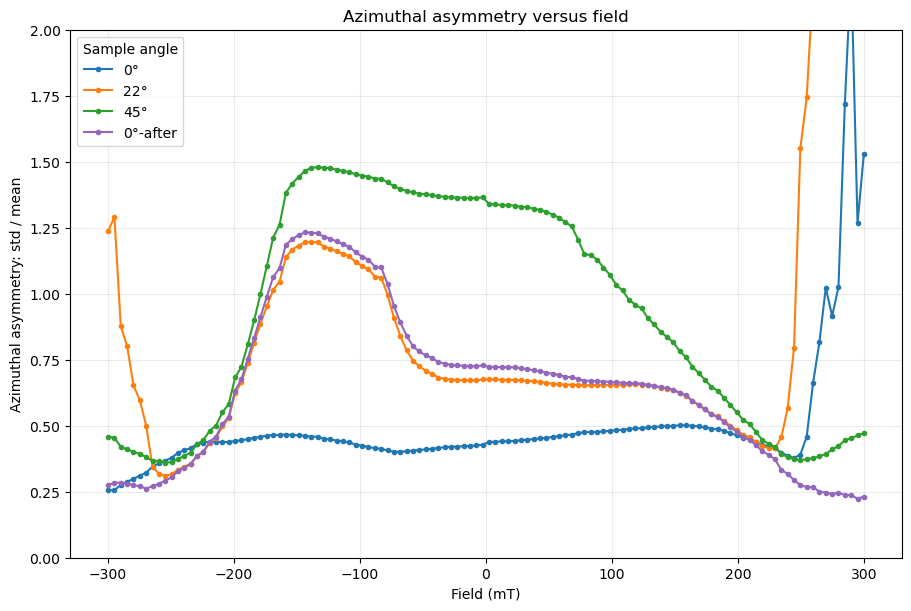

In [53]:
# 7. One plot: azimuthal asymmetry versus field for all three scans
fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
for label, color in zip(scan_ranges, ["tab:blue", "tab:orange", "tab:green" , "tab:purple"]):
    ax.plot(fields[label], asymmetry[label], "o-", markersize=3, label=label, color=color)
ax.set(xlabel="Field (mT)", ylabel="Azimuthal asymmetry: std / mean",
       title="Azimuthal asymmetry versus field")
ax.legend(title="Sample angle")
ax.set_ylim(0,2)
ax.grid(alpha=0.25)
plt.show()

In [54]:
# 8. Save only the comparison plot and its data
fig.savefig(output_folder / f"azimuthal_asymmetry_three_angles_{output_range}.png", dpi=180)
for label, indices in scan_ranges.items():
    tag = label.replace("°", "deg")
    scan_range = f"{indices[0]}-{indices[-1] + 1}"
    np.savetxt(azimuthal_folder / f"asymmetry_{tag}_{scan_range}.csv",
               np.c_[indices, fields[label], asymmetry[label], angular_means[label], angular_stds[label]],
               delimiter=",", header="scan_index,field_mT,std_over_mean,angular_mean,angular_std", comments="")
settings = dict(detector=detector, center_xy=[center_x, center_y], angular_bin_width=angular_bin_width,
                min_pixels=min_pixels, min_coverage=min_coverage,
                dark_scan_index=dark_scan_index, mask_path=str(mask_path) if mask_path else None,
                common_angles_deg=angles[common_bins].tolist(),
                scan_ranges={label: indices.tolist() for label, indices in scan_ranges.items()},
                fields={label: values.tolist() for label, values in fields.items()},
                failed_indices=failed_indices, metric="population std / mean; common angular bins across all three scans")
(azimuthal_folder / f"asymmetry_three_angles_{output_range}_settings.json").write_text(
    json.dumps(settings, indent=2) + "\n")
print("Comparison plot:", output_folder.resolve())
print("Numerical data:", azimuthal_folder.resolve())

Comparison plot: /Users/riccardo/Github/SEXTANTS_261105/output/cmos
Numerical data: /Users/riccardo/Github/SEXTANTS_261105/output/cmos/azimuthal
